# 05. Character features and model handoff

Owner: rdevasia25. Issue #5. Depends on completed #4.

## Goal

Compare character TF-IDF logistic regression with the completed word models. Select character C using training folds and save an ID-aligned handoff for error analysis.

## Setup

Character fragments can capture endings, spelling, and local punctuation patterns. This char_wb view lowercases and limits ngrams to word boundaries; original text remains available for later case-sensitive views.

In [1]:
import json, time, warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from threadpoolctl import threadpool_limits
get_ipython().run_line_magic("run", "./02_split_metrics.ipynb")
NAME = "05_char_comparison"
COMMAND = "uv run --locked jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=900 notebooks/05_char_comparison.ipynb"
CONFIG = {
    "C_candidates": [.25, 1., 4.],
    "vectorizer": {"analyzer": "char_wb", "ngram_range": [3, 5], "min_df": 2,
                   "max_features": 100000, "lowercase": True, "sublinear_tf": True,
                   "norm": "l2", "dtype": "float32", "strip_accents": None},
    "classifier": {"solver": "liblinear", "max_iter": 2000, "random_state": 42, "tol": 1e-4},
    "cv": {"n_splits": 3, "shuffle": True, "random_state": 42}, "threads": 1,
    "selection": "max mean training CV AUROC; first C breaks exact ties",
    "handoff": "use character only if CV gain over word handoff is greater than .002; otherwise keep cheaper word view",
    "bootstrap": {"draws": 2000, "seed": 42, "sampling": "paired class-stratified percentile 95%"},
}
CONFIG["notebook_source_sha256"] = value_hash(["".join(c["source"]) for c in json.loads((ROOT / "notebooks/05_char_comparison.ipynb").read_text())["cells"]])
START = time.perf_counter()


## Checks

Recheck the fixed split and word handoff hashes. Reuse exactly the three training folds from #4. Never fit character vocabulary on validation, unlabeled, or test rows.

In [2]:
parts = load_partitions()
train, validation = parts["train"], parts["validation"]
word_pointer = json.loads((ROOT / "artifacts/04_word_comparison/latest.json").read_text())
require(word_pointer["split_sha256"] == parts["split"]["split_sha256"], "Word split changed")
for path, expected in word_pointer["artifacts"].items():
    require(file_hash(ROOT / path) == expected, "Word handoff artifact changed")
require(file_hash(ROOT / word_pointer["result"]) == word_pointer["result_sha256"], "Word record changed")
word_record = json.loads((ROOT / word_pointer["result"]).read_text())
folds = list(StratifiedKFold(**CONFIG["cv"]).split(train.text, train.label))
CONFIG["fold_id_sha256"] = [{"fit": value_hash(train.id.iloc[a].tolist()), "score": value_hash(train.id.iloc[b].tolist())} for a,b in folds]
require(CONFIG["fold_id_sha256"] == word_record["config"]["fold_id_sha256"], "Training folds differ")
CONFIG["word_result"] = word_pointer["result"]
CONFIG["word_result_sha256"] = word_pointer["result_sha256"]
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
private = ROOT / "artifacts" / NAME / run_id
private.mkdir(parents=True, exist_ok=False)


## Method

Fit the entire character pipeline per C and fold. Save the CV choice before validation. Compare the selected word logistic model and the #4 handoff with the selected character model, including fit times and fold variation. Prefer the word handoff within .002 training-CV AUROC to control cost.

In [3]:
def make_character_model(c):
    vector = dict(CONFIG["vectorizer"])
    vector["ngram_range"], vector["dtype"] = tuple(vector["ngram_range"]), np.float32
    return Pipeline([("tfidf", TfidfVectorizer(**vector)),
                     ("classifier", LogisticRegression(C=c, **CONFIG["classifier"]))])

def predictions_for(model, frame):
    return pd.DataFrame({"id": frame.id.to_numpy(), "p_ai": class1_probabilities(model, frame.text)})

def paired_interval(truth, reference, treatment):
    merged = truth[["id", "label"]].merge(reference.rename(columns={"p_ai": "reference"}), on="id", validate="one_to_one")
    merged = merged.merge(treatment.rename(columns={"p_ai": "treatment"}), on="id", validate="one_to_one")
    require(len(merged) == len(truth), "Missing bootstrap IDs")
    y, a, b = (merged[key].to_numpy() for key in ["label", "reference", "treatment"])
    groups = [np.flatnonzero(y == label) for label in [0, 1]]
    rng = np.random.default_rng(42)
    values = []
    for _ in range(2000):
        idx = np.concatenate([rng.choice(group, len(group), replace=True) for group in groups])
        values.append(roc_auc_score(y[idx], b[idx]) - roc_auc_score(y[idx], a[idx]))
    low, high = np.quantile(values, [.025, .975])
    return {"delta_auroc": float(roc_auc_score(y, b) - roc_auc_score(y, a)), "ci_low": float(low), "ci_high": float(high)}


## Run

Time all candidates and the final fit. Load existing word models without refitting them; their saved CV and fit costs stay visible. Check class-1 inference and model reloads before saving the handoff.

In [4]:
artifacts = []
try:
    search_start = time.perf_counter()
    candidates = []
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        for c in CONFIG["C_candidates"]:
            scores, seconds = [], []
            oof = np.full(len(train), np.nan)
            candidate_start = time.perf_counter()
            error = None
            try:
                for fit_idx, score_idx in folds:
                    fold_start = time.perf_counter()
                    model = make_character_model(c)
                    model.fit(train.text.iloc[fit_idx], train.label.iloc[fit_idx])
                    oof[score_idx] = class1_probabilities(model, train.text.iloc[score_idx])
                    scores.append(float(roc_auc_score(train.label.iloc[score_idx], oof[score_idx])))
                    seconds.append(time.perf_counter() - fold_start)
            except Exception as exc:
                error = type(exc).__name__
            candidates.append({"C": c, "status": "failed" if error else "completed", "error_type": error,
                "fold_auroc": scores, "fold_seconds": seconds,
                "cv_mean": float(np.mean(scores)) if not error else None,
                "cv_std": float(np.std(scores)) if not error else None,
                "search_seconds": time.perf_counter() - candidate_start})
            path = private / f"C{c}_oof.csv"
            pd.DataFrame({"id": train.id, "p_ai": oof}).to_csv(path, index=False)
            artifacts.append(path)
    search_seconds = time.perf_counter() - search_start
    complete = [row for row in candidates if row["status"] == "completed"]
    require(bool(complete), "No completed character candidate")
    selected = max(complete, key=lambda row: row["cv_mean"])
    word_family = word_pointer["handoff_family"]
    word_cv = word_pointer["models"][word_family]["cv_mean"]
    handoff = "character" if selected["cv_mean"] > word_cv + .002 else "word"
    selection_path = ROOT / "results" / NAME / f"{run_id}-selection.json"
    save_new_json(selection_path, {"candidates": candidates, "selected_C": selected["C"],
        "handoff": handoff, "word_family": word_family, "word_cv_mean": word_cv,
        "validation_inspected": False, "config": CONFIG, "utc": datetime.now(timezone.utc).isoformat()})
    artifacts.append(selection_path)
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        model = make_character_model(selected["C"])
        fit_start = time.perf_counter()
        model.fit(train.text, train.label)
        fit_seconds = time.perf_counter() - fit_start
        evaluation_start = time.perf_counter()
        char_train, char_valid = predictions_for(model, train), predictions_for(model, validation)
        tm, vm = evaluate_predictions(train, char_train), evaluate_predictions(validation, char_valid)
        evaluation_seconds = time.perf_counter() - evaluation_start
        model_path = private / "character.joblib"
        joblib.dump(model, model_path)
        reload_difference = float(np.max(np.abs(class1_probabilities(joblib.load(model_path), validation.text) - char_valid.p_ai.to_numpy())))
        require(reload_difference <= 1e-12, "Character reload mismatch")
    train_path, validation_path = private / "character_train.csv", private / "character_validation.csv"
    char_train.to_csv(train_path, index=False); char_valid.to_csv(validation_path, index=False)
    artifacts.extend([model_path, train_path, validation_path])
    comparison_rows = []
    references = {}
    for family in dict.fromkeys(["logistic", word_family]):
        info = word_pointer["models"][family]
        pred = pd.read_csv(ROOT / info["validation_predictions"], dtype={"id": "string"}, float_precision="round_trip")
        evaluate_predictions(validation, pred)
        references[family] = pred
        prior = next(row for row in word_record["metrics"]["family_results"] if row["family"] == family)
        comparison_rows.append({"model": "word_" + family, **{k: prior[k] for k in
            ["train_auroc", "validation_auroc", "cv_mean", "cv_std", "fit_seconds", "evaluation_seconds"]},
            "search_seconds": sum(row["search_seconds"] for row in word_record["metrics"]["candidate_results"] if row["family"] == family)})
    comparison_rows.append({"model": "character_logistic", "train_auroc": tm["auroc"], "validation_auroc": vm["auroc"],
        "cv_mean": selected["cv_mean"], "cv_std": selected["cv_std"], "fit_seconds": fit_seconds,
        "evaluation_seconds": evaluation_seconds, "search_seconds": search_seconds})
    bootstrap_start = time.perf_counter()
    comparisons = [{"reference": "word_" + family, "treatment": "character_logistic", **paired_interval(validation, pred, char_valid)} for family, pred in references.items()]
    bootstrap_seconds = time.perf_counter() - bootstrap_start
    # Make a standalone copy of the selected pipeline for notebook 08.
    if handoff == "character":
        handoff_model, handoff_train, handoff_valid = model, char_train, char_valid
        handoff_cv = selected["cv_mean"]
    else:
        info = word_pointer["models"][word_family]
        handoff_model = joblib.load(ROOT / info["model"])
        handoff_train = pd.read_csv(ROOT / info["train_predictions"], dtype={"id": "string"}, float_precision="round_trip")
        handoff_valid = references[word_family]
        handoff_cv = word_cv
    evaluate_predictions(train, handoff_train); handoff_metrics = evaluate_predictions(validation, handoff_valid)
    handoff_model_path = private / "handoff.joblib"
    handoff_train_path, handoff_valid_path = private / "handoff_train.csv", private / "handoff_validation.csv"
    joblib.dump(handoff_model, handoff_model_path)
    handoff_train.to_csv(handoff_train_path, index=False); handoff_valid.to_csv(handoff_valid_path, index=False)
    with threadpool_limits(limits=1):
        require(np.allclose(class1_probabilities(joblib.load(handoff_model_path), validation.text), handoff_valid.p_ai, rtol=0, atol=1e-12), "Handoff predictions changed")
    artifacts.extend([handoff_model_path, handoff_train_path, handoff_valid_path])
except Exception as exc:
    record_run(NAME, COMMAND, CONFIG, SEED, len(train), len(validation),
        {"validation_auroc": None, "candidates": locals().get("candidates", [])}, time.perf_counter() - START,
        status="failed", error_type=type(exc).__name__)
    raise RuntimeError("Character comparison failed; see safe record.") from None


## Results

Confidence intervals condition on fitted models and the reused validation sample. They do not include training or model-selection variability. Costs come from separate timed runs, so small timing differences can be machine noise.

,C,status,error_type,fold_auroc,fold_seconds,cv_mean,cv_std,search_seconds
0,0.25,completed,None,"[0.8904208810823395, 0.9000985253809705, 0.913...","[7.78492304100655, 6.841696749965195, 7.272888...",0.901208,0.009293,21.899578
1,1.00,completed,None,"[0.9151258954168826, 0.9189246337071525, 0.927...","[7.346441416011658, 6.984435292019043, 6.48140...",0.920601,0.005290,20.812321
2,4.00,completed,None,"[0.9255014278307208, 0.9256572014067985, 0.933...","[6.985824666044209, 7.327189915988129, 8.08123...",0.928301,0.003850,22.394293


,model,train_auroc,validation_auroc,cv_mean,cv_std,fit_seconds,evaluation_seconds,search_seconds
0,word_logistic,0.999925,0.941252,0.936100,0.002987,2.784756,1.326397,20.832921
1,character_logistic,0.998412,0.938334,0.928301,0.003850,8.594038,9.283780,65.164445


,reference,treatment,delta_auroc,ci_low,ci_high
0,word_logistic,character_logistic,-0.002918,-0.009703,0.00398


Selected character C: 4.0; handoff: word; CV AUROC: 0.936100
Character search: 65.164s; fit: 8.594s; reload difference: 0


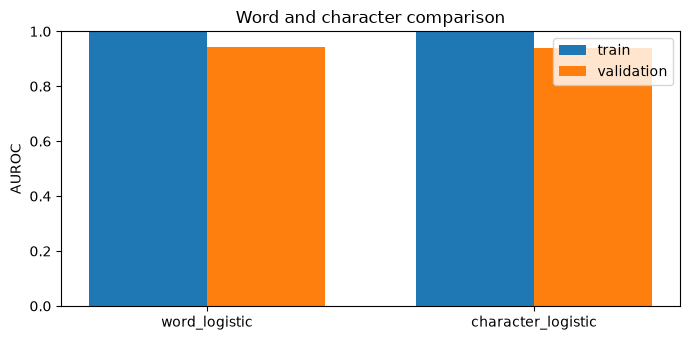

In [5]:
display(pd.DataFrame(candidates))
display(pd.DataFrame(comparison_rows))
display(pd.DataFrame(comparisons))
print(f"Selected character C: {selected['C']}; handoff: {handoff}; CV AUROC: {handoff_cv:.6f}")
print(f"Character search: {search_seconds:.3f}s; fit: {fit_seconds:.3f}s; reload difference: {reload_difference:.3g}")
fig, ax = plt.subplots(figsize=(7, 3.5))
locations = np.arange(len(comparison_rows))
for partition, offset in [("train", -.18), ("validation", .18)]:
    ax.bar(locations + offset, [row[f"{partition}_auroc"] for row in comparison_rows], width=.36, label=partition)
ax.set(xticks=locations, xticklabels=[row["model"] for row in comparison_rows], ylim=(0,1), ylabel="AUROC", title="Word and character comparison")
ax.legend(); fig.tight_layout()
plot_path = private / "comparison.png"
fig.savefig(plot_path, dpi=140); artifacts.append(plot_path)
plt.show()


## Takeaway

- Tried character C values on the same training folds as the word search.
- The measured table keeps both representations, including the losing arm and its cost.
- Next: hand the selected pipeline and aligned probabilities to #8. Keep raw case and punctuation for later experiments.

## Save

The private pointer `artifacts/05_char_comparison/latest.json` exposes a standalone model, train/validation predictions, source config, class-1 interface, and hashes for #8. No text or row prediction is committed.

In [6]:
metrics = {"validation_auroc": handoff_metrics["auroc"], "candidate_results": candidates,
    "comparison_results": comparison_rows, "paired_comparisons": comparisons, "selected_C": selected["C"],
    "handoff": handoff, "handoff_cv_mean": handoff_cv, "search_seconds": search_seconds,
    "bootstrap_seconds": bootstrap_seconds, "max_reload_difference": reload_difference}
CONFIG["extra_versions"] = {name: importlib.metadata.version(name) for name in ["joblib", "matplotlib", "threadpoolctl"]}
record_path = record_run(NAME, COMMAND, CONFIG, SEED, len(train), len(validation), metrics, time.perf_counter() - START, artifacts=artifacts)
pointer = {"result": str(record_path.relative_to(ROOT)), "result_sha256": file_hash(record_path),
    "split_sha256": parts["split"]["split_sha256"], "handoff": handoff, "word_family": word_family,
    "selected_character_C": selected["C"], "model": str(handoff_model_path.relative_to(ROOT)),
    "train_predictions": str(handoff_train_path.relative_to(ROOT)),
    "validation_predictions": str(handoff_valid_path.relative_to(ROOT)),
    "class1_interface": "class1_probabilities(joblib.load(model), texts)",
    "artifacts": {str(p.relative_to(ROOT)): file_hash(p) for p in artifacts}}
pointer_path = ROOT / "artifacts" / NAME / "latest.json"
temporary = pointer_path.with_suffix(".tmp")
temporary.write_text(json.dumps(pointer, indent=2, sort_keys=True) + "\n"); temporary.replace(pointer_path)
print("Saved measured comparison and checked error-analysis handoff.")


Saved measured comparison and checked error-analysis handoff.
